In [2]:
# ============================================================
# PHASE 0
# STEP 0.1: IMPORT BASIC LIBRARIES
# ============================================================

import pandas as pd
import numpy as np

In [3]:
# ============================================================
# PHASE 0
# STEP 0.2: LOAD FEATURE-ENGINEERED DATA
# ============================================================

df = pd.read_csv(
    "/content/2.0_Customer_Churn_Feature_Engineered (1).csv"
)

print("Dataset loaded successfully.")

Dataset loaded successfully.


In [4]:
# ============================================================
# PHASE 0
# STEP 0.3: VERIFY DATASET DIMENSIONS
# ============================================================

print("=" * 60)
print("DATASET DIMENSIONS")
print("=" * 60)

print("Rows    :", df.shape[0])
print("Columns :", df.shape[1])

DATASET DIMENSIONS
Rows    : 7021
Columns : 46


In [5]:
# ============================================================
# PHASE 0
# STEP 0.4: VERIFY COLUMN NAMES
# ============================================================

print("=" * 60)
print("COLUMN NAMES")
print("=" * 60)

for i, column in enumerate(df.columns, start=1):
    print(f"{i:02d}. {column}")

COLUMN NAMES
01. gender
02. SeniorCitizen
03. Partner
04. Dependents
05. tenure
06. PhoneService
07. MultipleLines
08. InternetService
09. OnlineSecurity
10. OnlineBackup
11. DeviceProtection
12. TechSupport
13. StreamingTV
14. StreamingMovies
15. Contract
16. PaperlessBilling
17. PaymentMethod
18. MonthlyCharges
19. TotalCharges
20. Churn
21. TenureGroup
22. IsNewCustomer
23. LongTermCustomer
24. CustomerAgeScore
25. ServiceCount
26. EntertainmentServices
27. SecurityServices
28. PremiumUser
29. MultiServiceUser
30. ChargeCategory
31. RevenueSegment
32. AvgChargePerMonth
33. HighMonthlyCharge
34. HasDependents
35. FamilyCustomer
36. IndependentCustomer
37. LongTermContract
38. AutoPayment
39. ElectronicPayment
40. PaperlessCustomer
41. InternetUser
42. FiberCustomer
43. InternetAddOnCount
44. CustomerValueScore
45. LoyaltyScore
46. HighRiskCustomer


In [6]:
# ============================================================
# PHASE 0
# STEP 0.5: PREVIEW THE DATA
# ============================================================

df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,LongTermContract,AutoPayment,ElectronicPayment,PaperlessCustomer,InternetUser,FiberCustomer,InternetAddOnCount,CustomerValueScore,LoyaltyScore,HighRiskCustomer
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,...,0,0,1,1,1,0,1,1.20,1,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,...,1,0,0,0,1,0,2,4.05,7,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,...,0,0,0,1,1,0,2,2.64,3,0
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,...,1,1,0,0,1,0,3,4.14,9,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,...,0,0,1,1,1,1,0,2.27,1,1


In [7]:
# ============================================================
# PHASE 0
# STEP 0.6: CHECK DATA TYPES
# ============================================================

print("=" * 60)
print("DATA TYPES")
print("=" * 60)

print(df.dtypes)

DATA TYPES
gender                    object
SeniorCitizen              int64
Partner                   object
Dependents                object
tenure                     int64
PhoneService              object
MultipleLines             object
InternetService           object
OnlineSecurity            object
OnlineBackup              object
DeviceProtection          object
TechSupport               object
StreamingTV               object
StreamingMovies           object
Contract                  object
PaperlessBilling          object
PaymentMethod             object
MonthlyCharges           float64
TotalCharges             float64
Churn                      int64
TenureGroup               object
IsNewCustomer              int64
LongTermCustomer           int64
CustomerAgeScore         float64
ServiceCount               int64
EntertainmentServices      int64
SecurityServices           int64
PremiumUser                int64
MultiServiceUser           int64
ChargeCategory            object

In [8]:
# ============================================================
# PHASE 0
# STEP 0.7: CHECK MISSING VALUES
# ============================================================

missing_values = df.isnull().sum()

missing_values = missing_values[
    missing_values > 0
].sort_values(ascending=False)

print("=" * 60)
print("MISSING VALUES")
print("=" * 60)

if len(missing_values) == 0:
    print("No missing values found.")
else:
    print(missing_values)

MISSING VALUES
No missing values found.


In [9]:
# ============================================================
# PHASE 0
# STEP 0.8: CHECK DUPLICATE ROWS
# ============================================================

duplicate_count = df.duplicated().sum()

print("=" * 60)
print("DUPLICATE CHECK")
print("=" * 60)

print("Duplicate rows :", duplicate_count)

DUPLICATE CHECK
Duplicate rows : 0


In [10]:
# ============================================================
# PHASE 0
# STEP 0.9: VERIFY TARGET VARIABLE
# ============================================================

print("=" * 60)
print("TARGET VARIABLE")
print("=" * 60)

print(df["Churn"].value_counts())

print("\nPercentage Distribution:")
print(
    df["Churn"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

TARGET VARIABLE
Churn
0    5164
1    1857
Name: count, dtype: int64

Percentage Distribution:
Churn
0    73.55
1    26.45
Name: proportion, dtype: float64


In [11]:
# ============================================================
# PHASE 0
# STEP 0.10: DEFINE FEATURES AND TARGET
# ============================================================

X = df.drop(columns=["Churn"])
y = df["Churn"]

print("=" * 60)
print("FEATURES AND TARGET")
print("=" * 60)

print("Feature matrix shape :", X.shape)
print("Target shape         :", y.shape)

FEATURES AND TARGET
Feature matrix shape : (7021, 45)
Target shape         : (7021,)


In [12]:
# ============================================================
# PHASE 1
# STEP 1.1: IMPORT TRAIN TEST SPLIT
# ============================================================

from sklearn.model_selection import train_test_split

In [13]:
# ============================================================
# PHASE 1
# STEP 1.2: CREATE TRAIN AND FINAL TEST SETS
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [14]:
# ============================================================
# PHASE 1
# STEP 1.3: VERIFY SPLIT DIMENSIONS
# ============================================================

print("=" * 60)
print("TRAIN / TEST SPLIT")
print("=" * 60)

print("X_train :", X_train.shape)
print("X_test  :", X_test.shape)
print("y_train :", y_train.shape)
print("y_test  :", y_test.shape)

TRAIN / TEST SPLIT
X_train : (5616, 45)
X_test  : (1405, 45)
y_train : (5616,)
y_test  : (1405,)


In [15]:
# ============================================================
# PHASE 1
# STEP 1.4: VERIFY TARGET DISTRIBUTION AFTER SPLIT
# ============================================================

train_churn_rate = y_train.mean() * 100
test_churn_rate  = y_test.mean() * 100

print("=" * 60)
print("CHURN DISTRIBUTION AFTER SPLIT")
print("=" * 60)

print(f"Training Churn Rate : {train_churn_rate:.2f}%")
print(f"Test Churn Rate     : {test_churn_rate:.2f}%")

CHURN DISTRIBUTION AFTER SPLIT
Training Churn Rate : 26.44%
Test Churn Rate     : 26.48%


**2A. Rebuild a training-only analysis dataset**

In [16]:
# ============================================================
# PHASE 2
# STEP 2.1: CREATE TRAINING-ONLY ANALYSIS DATA
# ============================================================

train_df = X_train.copy()
train_df["Churn"] = y_train

print("Training analysis dataset shape:", train_df.shape)

Training analysis dataset shape: (5616, 46)


In [17]:
# ============================================================
# STEP 2.2: IDENTIFY FEATURE TYPES
# ============================================================

numerical_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("=" * 60)
print("FEATURE TYPE SUMMARY")
print("=" * 60)

print("Numerical features   :", len(numerical_features))
print("Categorical features :", len(categorical_features))

print("\nNumerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

FEATURE TYPE SUMMARY
Numerical features   : 27
Categorical features : 18

Numerical Features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'IsNewCustomer', 'LongTermCustomer', 'CustomerAgeScore', 'ServiceCount', 'EntertainmentServices', 'SecurityServices', 'PremiumUser', 'MultiServiceUser', 'AvgChargePerMonth', 'HighMonthlyCharge', 'HasDependents', 'FamilyCustomer', 'IndependentCustomer', 'LongTermContract', 'AutoPayment', 'ElectronicPayment', 'PaperlessCustomer', 'InternetUser', 'FiberCustomer', 'InternetAddOnCount', 'CustomerValueScore', 'LoyaltyScore', 'HighRiskCustomer']

Categorical Features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TenureGroup', 'ChargeCategory', 'RevenueSegment']


In [18]:
# ============================================================
# STEP 2.3: NUMERICAL CORRELATION MATRIX
# ============================================================

corr_matrix = X_train[numerical_features].corr()

print("=" * 60)
print("TRAINING-ONLY CORRELATION MATRIX")
print("=" * 60)

print(corr_matrix.round(2))

TRAINING-ONLY CORRELATION MATRIX
                       SeniorCitizen  tenure  MonthlyCharges  TotalCharges  \
SeniorCitizen                   1.00    0.02            0.22          0.11   
tenure                          0.02    1.00            0.25          0.83   
MonthlyCharges                  0.22    0.25            1.00          0.65   
TotalCharges                    0.11    0.83            0.65          1.00   
IsNewCustomer                  -0.03   -0.75           -0.18         -0.59   
LongTermCustomer                0.03    0.86            0.21          0.69   
CustomerAgeScore                0.02    1.00            0.25          0.83   
ServiceCount                    0.10    0.53            0.80          0.80   
EntertainmentServices           0.13    0.33            0.72          0.59   
SecurityServices                0.01    0.51            0.57          0.68   
PremiumUser                     0.04    0.47            0.51          0.67   
MultiServiceUser               

In [19]:
X_train[numerical_features]

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,IsNewCustomer,LongTermCustomer,CustomerAgeScore,ServiceCount,EntertainmentServices,SecurityServices,...,LongTermContract,AutoPayment,ElectronicPayment,PaperlessCustomer,InternetUser,FiberCustomer,InternetAddOnCount,CustomerValueScore,LoyaltyScore,HighRiskCustomer
2624,0,2,70.70,140.70,1,0,0.028,1,0,0,...,0,1,0,0,1,1,0,2.27,3,1
2645,0,15,84.35,1302.65,0,0,0.208,4,0,2,...,0,1,0,1,1,1,2,4.35,6,0
1416,0,67,89.55,6373.10,0,1,0.931,4,1,1,...,0,1,0,1,1,1,2,6.66,10,0
5760,0,5,65.60,339.90,1,0,0.069,4,1,2,...,0,1,0,1,1,0,3,3.46,6,0
2420,0,26,20.30,511.25,0,1,0.361,1,0,0,...,0,0,1,1,0,0,0,2.00,5,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6678,0,5,96.55,500.10,1,0,0.069,5,1,2,...,0,0,1,0,1,1,3,4.65,5,1
2089,0,18,19.65,391.70,0,0,0.250,1,0,0,...,0,0,0,0,0,0,0,1.65,1,0
4980,0,58,106.45,6145.85,0,1,0.806,6,2,3,...,1,0,1,1,1,1,5,7.51,10,0
6861,1,71,99.65,7181.25,0,1,0.986,6,1,3,...,1,1,0,1,1,1,4,7.88,12,0


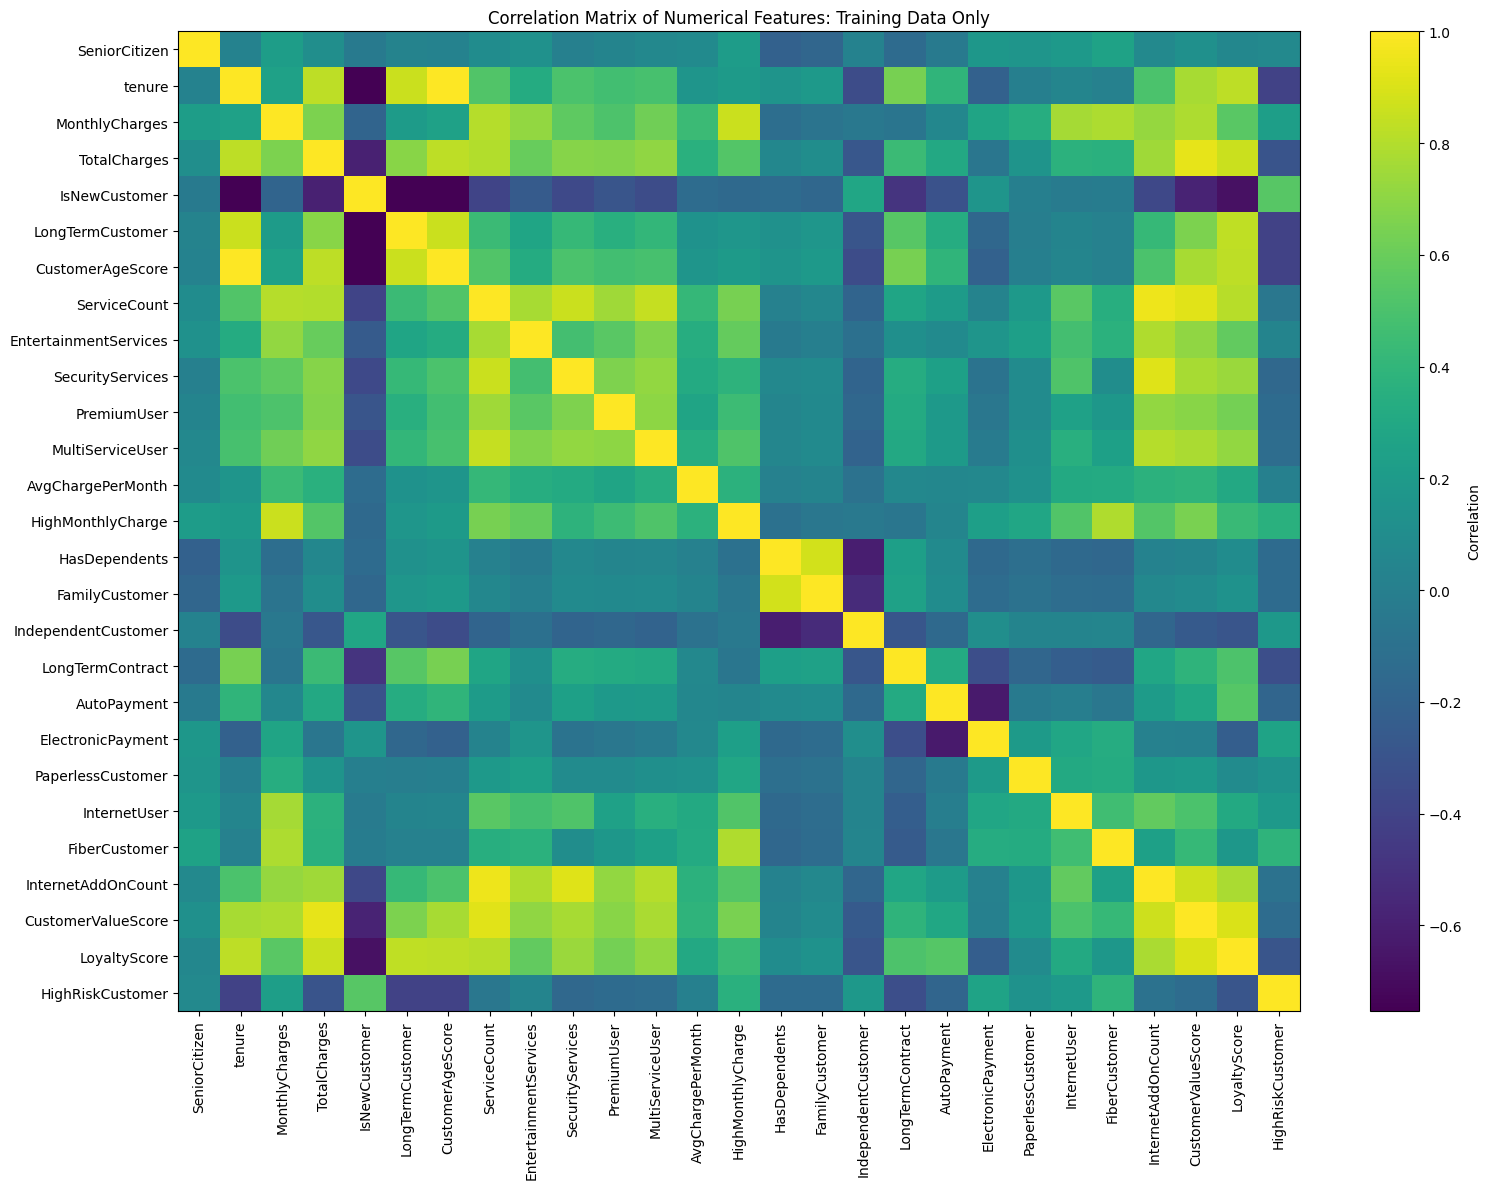

In [20]:
import matplotlib.pyplot as plt

plt.figure(figsize=(16, 12))

plt.imshow(
    corr_matrix,
    aspect="auto"
)

plt.colorbar(label="Correlation")

plt.xticks(
    range(len(corr_matrix.columns)),
    corr_matrix.columns,
    rotation=90
)

plt.yticks(
    range(len(corr_matrix.columns)),
    corr_matrix.columns
)

plt.title("Correlation Matrix of Numerical Features: Training Data Only")
plt.tight_layout()
plt.show()

In [21]:
# ============================================================
# STEP 2.4: IDENTIFY HIGHLY CORRELATED NUMERICAL FEATURES
# ============================================================

correlation_threshold = 0.80

corr_pairs = []

for i in range(len(corr_matrix.columns)):
    for j in range(i):

        correlation = corr_matrix.iloc[i, j]

        if abs(correlation) >= correlation_threshold:

            corr_pairs.append({
                "Feature_1": corr_matrix.columns[i],
                "Feature_2": corr_matrix.columns[j],
                "Correlation": correlation
            })

high_corr_df = pd.DataFrame(corr_pairs)

if not high_corr_df.empty:
    high_corr_df["Absolute_Correlation"] = (
        high_corr_df["Correlation"].abs()
    )

    high_corr_df = high_corr_df.sort_values(
        "Absolute_Correlation",
        ascending=False
    )

print("=" * 70)
print("HIGHLY CORRELATED FEATURE PAIRS")
print("=" * 70)

if high_corr_df.empty:
    print("No feature pairs found above the threshold.")
else:
    print(high_corr_df)

HIGHLY CORRELATED FEATURE PAIRS
             Feature_1           Feature_2  Correlation  Absolute_Correlation
2     CustomerAgeScore              tenure     1.000000              1.000000
10  InternetAddOnCount        ServiceCount     0.952357              0.952357
13  CustomerValueScore        TotalCharges     0.933315              0.933315
14  CustomerValueScore        ServiceCount     0.921591              0.921591
11  InternetAddOnCount    SecurityServices     0.913955              0.913955
21        LoyaltyScore  CustomerValueScore     0.901834              0.901834
9       FamilyCustomer       HasDependents     0.881152              0.881152
15  CustomerValueScore  InternetAddOnCount     0.863877              0.863877
1     LongTermCustomer              tenure     0.858886              0.858886
4     CustomerAgeScore    LongTermCustomer     0.858866              0.858866
6     SecurityServices        ServiceCount     0.857526              0.857526
17        LoyaltyScore        To

In [22]:
# ============================================================
# STEP 2.5: VARIANCE INFLATION FACTOR (VIF)
# ============================================================

from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

vif_data = X_train[numerical_features].copy()

# Remove zero-variance columns if any
constant_columns = [
    col for col in vif_data.columns
    if vif_data[col].nunique() <= 1
]

if constant_columns:
    print("Removing constant columns from VIF:", constant_columns)
    vif_data = vif_data.drop(columns=constant_columns)

# Add intercept
vif_with_constant = add_constant(vif_data)

vif_results = pd.DataFrame()

vif_results["Feature"] = vif_with_constant.columns

vif_results["VIF"] = [
    variance_inflation_factor(
        vif_with_constant.values,
        i
    )
    for i in range(vif_with_constant.shape[1])
]

# Drop intercept from display
vif_results = vif_results[
    vif_results["Feature"] != "const"
].sort_values(
    "VIF",
    ascending=False
)

print("=" * 60)
print("VARIANCE INFLATION FACTOR")
print("=" * 60)

print(vif_results)

/tmp/ipykernel_655/1492972642.py:28: UserWarning: The design matrix is poorly conditioned (condition number=1.34e+16). VIF calculations may be numerically unstable.
  variance_inflation_factor(
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatri

VARIANCE INFLATION FACTOR
                  Feature           VIF
9   EntertainmentServices  1.000800e+15
10       SecurityServices  1.000800e+15
6        LongTermCustomer  1.000800e+15
8            ServiceCount  1.000800e+15
24     InternetAddOnCount  1.000800e+15
26           LoyaltyScore  1.000800e+15
19            AutoPayment  1.000800e+15
7        CustomerAgeScore  1.770080e+06
2                  tenure  1.619546e+06
25     CustomerValueScore  5.538908e+05
3          MonthlyCharges  6.983556e+04
23          FiberCustomer  2.094157e+01
4            TotalCharges  1.753582e+01
22           InternetUser  1.160723e+01
14      HighMonthlyCharge  5.862721e+00
15          HasDependents  5.387040e+00
16         FamilyCustomer  4.595481e+00
5           IsNewCustomer  3.973817e+00
12       MultiServiceUser  3.920633e+00
27       HighRiskCustomer  3.188905e+00
11            PremiumUser  2.849102e+00
18       LongTermContract  2.249049e+00
20      ElectronicPayment  2.188781e+00
17    Independ

/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stat

In [23]:
# ============================================================
# STEP 2.6: CHI-SQUARE TEST FOR CATEGORICAL FEATURES
# TRAINING DATA ONLY
# ============================================================

from scipy.stats import chi2_contingency

chi_results = []

for feature in categorical_features:

    contingency_table = pd.crosstab(
        X_train[feature],
        y_train
    )

    chi2, p_value, dof, expected = chi2_contingency(
        contingency_table
    )

    chi_results.append({
        "Feature": feature,
        "Chi2_Statistic": chi2,
        "P_Value": p_value,
        "Degrees_of_Freedom": dof,
        "Significant_5pct": p_value < 0.05
    })

chi_df = pd.DataFrame(
    chi_results
).sort_values(
    "Chi2_Statistic",
    ascending=False
)

print("=" * 70)
print("CHI-SQUARE RESULTS: TRAINING DATA ONLY")
print("=" * 70)

print(chi_df)

CHI-SQUARE RESULTS: TRAINING DATA ONLY
             Feature  Chi2_Statistic        P_Value  Degrees_of_Freedom  \
12          Contract      942.639429  2.034459e-205                   2   
6     OnlineSecurity      689.000305  2.429320e-150                   2   
9        TechSupport      666.351962  2.011453e-145                   2   
15       TenureGroup      660.676448  7.055415e-143                   3   
5    InternetService      624.503129  2.459623e-136                   2   
14     PaymentMethod      524.748355  2.065777e-113                   3   
7       OnlineBackup      488.442641  8.630344e-107                   2   
8   DeviceProtection      446.062649   1.376342e-97                   2   
10       StreamingTV      314.789226   4.409488e-69                   2   
11   StreamingMovies      314.531005   5.017184e-69                   2   
17    RevenueSegment      251.097253   2.984862e-55                   2   
13  PaperlessBilling      210.003125   1.371463e-47          

In [24]:
# ============================================================
# STEP 2.7: ANOVA F-TEST FOR NUMERICAL FEATURES
# TRAINING DATA ONLY
# ============================================================

from sklearn.feature_selection import f_classif

X_train_num = X_train[numerical_features]

f_scores, p_values = f_classif(
    X_train_num,
    y_train
)

anova_df = pd.DataFrame({
    "Feature": numerical_features,
    "F_Statistic": f_scores,
    "P_Value": p_values
})

anova_df["Significant_5pct"] = (
    anova_df["P_Value"] < 0.05
)

anova_df = anova_df.sort_values(
    "F_Statistic",
    ascending=False
)

print("=" * 70)
print("ANOVA RESULTS: TRAINING DATA ONLY")
print("=" * 70)

print(anova_df)

ANOVA RESULTS: TRAINING DATA ONLY
                  Feature  F_Statistic        P_Value  Significant_5pct
17       LongTermContract  1100.867176  1.358740e-220              True
26       HighRiskCustomer   825.937976  1.410876e-169              True
1                  tenure   755.775885  3.316898e-156              True
6        CustomerAgeScore   755.654608  3.499236e-156              True
22          FiberCustomer   635.932556  5.110144e-133              True
4           IsNewCustomer   622.187347  2.492723e-130              True
5        LongTermCustomer   578.891586  8.013926e-122              True
19      ElectronicPayment   574.477975  5.949377e-121              True
25           LoyaltyScore   344.088660   1.341712e-74              True
21           InternetUser   326.479624   5.579785e-71              True
18            AutoPayment   254.556731   4.438533e-56              True
13      HighMonthlyCharge   246.479319   2.152532e-54              True
2          MonthlyCharges   24

In [25]:
# ============================================================
# STEP 2.8: PREPARE TRAINING DATA FOR MUTUAL INFORMATION
# ============================================================

from sklearn.preprocessing import OrdinalEncoder
from sklearn.feature_selection import mutual_info_classif

X_train_mi = X_train.copy()

mi_categorical = X_train_mi.select_dtypes(
    include=["object", "category"]
).columns

ordinal_encoder_mi = OrdinalEncoder(
    handle_unknown="use_encoded_value",
    unknown_value=-1
)

X_train_mi[mi_categorical] = (
    ordinal_encoder_mi.fit_transform(
        X_train_mi[mi_categorical]
    )
)

X_train_mi = X_train_mi.astype(float)

In [26]:
# ============================================================
# STEP 2.9: MUTUAL INFORMATION
# ============================================================

discrete_mask = [
    col in mi_categorical
    or X_train[col].nunique() <= 10
    for col in X_train.columns
]

mi_scores = mutual_info_classif(
    X_train_mi,
    y_train,
    discrete_features=discrete_mask,
    random_state=42
)

mi_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Mutual_Information": mi_scores
}).sort_values(
    "Mutual_Information",
    ascending=False
)

print("=" * 70)
print("MUTUAL INFORMATION: TRAINING DATA ONLY")
print("=" * 70)

print(mi_df)

MUTUAL INFORMATION: TRAINING DATA ONLY
                  Feature  Mutual_Information
14               Contract        9.788843e-02
35       LongTermContract        9.166471e-02
22       CustomerAgeScore        7.636375e-02
4                  tenure        6.682085e-02
8          OnlineSecurity        6.626170e-02
11            TechSupport        6.416356e-02
19            TenureGroup        5.975059e-02
7         InternetService        5.971765e-02
44       HighRiskCustomer        5.577209e-02
40          FiberCustomer        5.136077e-02
9            OnlineBackup        4.824309e-02
20          IsNewCustomer        4.747993e-02
21       LongTermCustomer        4.709566e-02
43           LoyaltyScore        4.689202e-02
16          PaymentMethod        4.520372e-02
37      ElectronicPayment        4.478057e-02
10       DeviceProtection        4.475974e-02
18           TotalCharges        4.222387e-02
17         MonthlyCharges        4.050665e-02
30      AvgChargePerMonth        3.457615

In [27]:
# ============================================================
# STEP 2.10: RANDOM FOREST FEATURE IMPORTANCE
# TRAINING DATA ONLY
# ============================================================

from sklearn.ensemble import RandomForestClassifier

rf_selector = RandomForestClassifier(
    n_estimators=500,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

rf_selector.fit(
    X_train_mi,
    y_train
)

rf_importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "RF_Importance": rf_selector.feature_importances_
}).sort_values(
    "RF_Importance",
    ascending=False
)

print("=" * 70)
print("RANDOM FOREST FEATURE IMPORTANCE")
print("=" * 70)

print(rf_importance_df)

RANDOM FOREST FEATURE IMPORTANCE
                  Feature  RF_Importance
17         MonthlyCharges       0.080494
18           TotalCharges       0.079409
30      AvgChargePerMonth       0.078356
4                  tenure       0.067067
22       CustomerAgeScore       0.066330
42     CustomerValueScore       0.066310
14               Contract       0.059751
35       LongTermContract       0.045126
8          OnlineSecurity       0.035600
11            TechSupport       0.030463
40          FiberCustomer       0.027473
43           LoyaltyScore       0.025009
16          PaymentMethod       0.019023
37      ElectronicPayment       0.017940
25       SecurityServices       0.017584
0                  gender       0.015731
41     InternetAddOnCount       0.014827
19            TenureGroup       0.014555
23           ServiceCount       0.014267
9            OnlineBackup       0.014077
7         InternetService       0.012808
38      PaperlessCustomer       0.012180
44       HighRiskCustome

In [28]:
# ============================================================
# STEP 2.11: FEATURE SELECTION DECISION SCORECARD
# ============================================================
#
# Purpose:
# Combine evidence from:
# 1. ANOVA statistical significance
# 2. Mutual Information
# 3. Random Forest feature importance
# 4. Redundancy / interpretability / domain judgement
#
# This scorecard makes the final feature-selection decision
# transparent before moving to Phase 3.
# ============================================================

import pandas as pd
import numpy as np


# ------------------------------------------------------------
# 1. Start with every predictor
# ------------------------------------------------------------

feature_scorecard = pd.DataFrame({
    "Feature": X_train.columns
})


# ------------------------------------------------------------
# 2. Add ANOVA results
# Only numerical features have ANOVA results.
# Categorical features will remain NaN here.
# ------------------------------------------------------------

feature_scorecard = feature_scorecard.merge(
    anova_df[
        [
            "Feature",
            "F_Statistic",
            "P_Value",
            "Significant_5pct"
        ]
    ],
    on="Feature",
    how="left"
)


# ------------------------------------------------------------
# 3. Add Mutual Information
# ------------------------------------------------------------

feature_scorecard = feature_scorecard.merge(
    mi_df[
        [
            "Feature",
            "Mutual_Information"
        ]
    ],
    on="Feature",
    how="left"
)


# ------------------------------------------------------------
# 4. Add Random Forest importance
# ------------------------------------------------------------

feature_scorecard = feature_scorecard.merge(
    rf_importance_df[
        [
            "Feature",
            "RF_Importance"
        ]
    ],
    on="Feature",
    how="left"
)


# ------------------------------------------------------------
# 5. Create ranks for MI and RF importance
#
# Rank 1 = strongest feature according to that method.
# ------------------------------------------------------------

feature_scorecard["MI_Rank"] = (
    feature_scorecard["Mutual_Information"]
    .rank(method="min", ascending=False)
)

feature_scorecard["RF_Rank"] = (
    feature_scorecard["RF_Importance"]
    .rank(method="min", ascending=False)
)


# ------------------------------------------------------------
# 6. Add simple evidence indicators
#
# These are NOT automatic final-selection rules.
# They simply summarize the diagnostic evidence.
# ------------------------------------------------------------

feature_scorecard["ANOVA_Evidence"] = np.where(
    feature_scorecard["Significant_5pct"] == True,
    "Strong",
    np.where(
        feature_scorecard["Significant_5pct"] == False,
        "Weak",
        "N/A"
    )
)


# Top 20 is used here only as an easy way of identifying
# relatively strong MI / RF evidence.
# It does NOT mean every top-20 feature must be selected.

feature_scorecard["MI_Evidence"] = np.where(
    feature_scorecard["MI_Rank"] <= 20,
    "Strong",
    "Weak"
)

feature_scorecard["RF_Evidence"] = np.where(
    feature_scorecard["RF_Rank"] <= 20,
    "Strong",
    "Weak"
)


# ------------------------------------------------------------
# 7. Features selected after combining:
#
# - statistical evidence
# - information content
# - RF predictive importance
# - redundancy
# - interpretability
# - business relevance
# ------------------------------------------------------------

final_selected_features = [

    # Customer lifecycle
    "tenure",
    "TenureGroup",
    "IsNewCustomer",

    # Contract
    "Contract",

    # Pricing / revenue
    "MonthlyCharges",
    "TotalCharges",
    "AvgChargePerMonth",

    # Internet / services
    "InternetService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "ServiceCount",

    # Billing behaviour
    "PaymentMethod",
    "PaperlessBilling",

    # Customer profile
    "SeniorCitizen",
    "Partner",
    "Dependents",

    # Engineered risk signal
    "HighRiskCustomer"
]


# ------------------------------------------------------------
# 8. Explain important redundancy decisions
# ------------------------------------------------------------

decision_reason = {

    # -----------------------------
    # Selected features
    # -----------------------------

    "tenure":
        "KEEP: Strong churn signal and core interpretable lifecycle variable.",

    "TenureGroup":
        "KEEP: Captures lifecycle stages and possible non-linear tenure effects.",

    "IsNewCustomer":
        "KEEP: Captures specific early-customer churn risk.",

    "Contract":
        "KEEP: Strong MI/RF evidence and richer than derived LongTermContract.",

    "MonthlyCharges":
        "KEEP: Strong predictive importance and important pricing signal.",

    "TotalCharges":
        "KEEP: Captures accumulated customer value and tenure-spend behaviour.",

    "AvgChargePerMonth":
        "KEEP: Weak ANOVA alone but strong RF evidence; may contribute jointly/non-linearly.",

    "InternetService":
        "KEEP: Strong churn-related service characteristic.",

    "OnlineSecurity":
        "KEEP: Strong MI and RF evidence; meaningful service-risk signal.",

    "OnlineBackup":
        "KEEP: Adds distinct information about service adoption.",

    "DeviceProtection":
        "KEEP: Adds information about customer service portfolio.",

    "TechSupport":
        "KEEP: Strong MI/RF evidence and interpretable retention-related service.",

    "ServiceCount":
        "KEEP: Summarises overall customer service engagement.",

    "PaymentMethod":
        "KEEP: Strong MI evidence and important billing behaviour.",

    "PaperlessBilling":
        "KEEP: Billing behaviour associated with churn.",

    "SeniorCitizen":
        "KEEP: Distinct demographic signal.",

    "Partner":
        "KEEP: Distinct household/customer profile information.",

    "Dependents":
        "KEEP: Distinct household/customer profile information.",

    "HighRiskCustomer":
        "KEEP: Engineered interaction capturing new + high-charge + short-contract risk.",


    # -----------------------------
    # Examples of dropped redundant
    # engineered features
    # -----------------------------

    "CustomerAgeScore":
        "DROP: Strong signal but largely derived from tenure; redundant.",

    "LongTermCustomer":
        "DROP: Derived from tenure; information already represented by tenure/lifecycle variables.",

    "LongTermContract":
        "DROP: Strong feature but directly derived from Contract; Contract is richer.",

    "HighMonthlyCharge":
        "DROP: Derived threshold version of MonthlyCharges.",

    "FiberCustomer":
        "DROP: Derived from InternetService; original variable contains richer categories.",

    "ElectronicPayment":
        "DROP: Derived from PaymentMethod; original feature is richer.",

    "PaperlessCustomer":
        "DROP: Duplicates PaperlessBilling information.",

    "SecurityServices":
        "DROP: Aggregated information already represented by individual service variables.",

    "EntertainmentServices":
        "DROP: Aggregated service variable; weaker unique contribution.",

    "InternetAddOnCount":
        "DROP: Overlaps strongly with ServiceCount and individual internet services.",

    "CustomerValueScore":
        "DROP: Engineered combination overlaps with tenure and charge variables.",

    "LoyaltyScore":
        "DROP: Engineered combination overlaps with tenure/contract/service behaviour.",

    "PremiumUser":
        "DROP: Derived from ServiceCount; ServiceCount retains more information."
}


# ------------------------------------------------------------
# 9. Final decision column
# ------------------------------------------------------------

feature_scorecard["Decision"] = np.where(
    feature_scorecard["Feature"].isin(final_selected_features),
    "KEEP",
    "DROP"
)


# ------------------------------------------------------------
# 10. Attach explanation
# ------------------------------------------------------------

feature_scorecard["Reason"] = (
    feature_scorecard["Feature"]
    .map(decision_reason)
    .fillna(
        "DROP: Lower unique contribution, redundancy, "
        "or weaker combined feature-selection evidence."
    )
)


# ------------------------------------------------------------
# 11. Add number of strong diagnostic signals
#
# This is for interpretation only.
# It is NOT being used as a strict selection rule.
# ------------------------------------------------------------

feature_scorecard["Evidence_Count"] = (

    (feature_scorecard["ANOVA_Evidence"] == "Strong").astype(int)

    +

    (feature_scorecard["MI_Evidence"] == "Strong").astype(int)

    +

    (feature_scorecard["RF_Evidence"] == "Strong").astype(int)
)


# ------------------------------------------------------------
# 12. Sort scorecard
# Keep selected features first, then stronger evidence.
# ------------------------------------------------------------

feature_scorecard["Decision_Order"] = (
    feature_scorecard["Decision"]
    .map({
        "KEEP": 0,
        "DROP": 1
    })
)

feature_scorecard = (
    feature_scorecard
    .sort_values(
        by=[
            "Decision_Order",
            "Evidence_Count",
            "Mutual_Information",
            "RF_Importance"
        ],
        ascending=[
            True,
            False,
            False,
            False
        ]
    )
    .drop(columns="Decision_Order")
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 13. Display final scorecard
# ------------------------------------------------------------

pd.set_option("display.max_rows", None)
pd.set_option("display.max_colwidth", 120)

print("=" * 120)
print("FINAL FEATURE-SELECTION DECISION SCORECARD")
print("=" * 120)

display(
    feature_scorecard[
        [
            "Feature",
            "F_Statistic",
            "P_Value",
            "ANOVA_Evidence",
            "Mutual_Information",
            "MI_Rank",
            "MI_Evidence",
            "RF_Importance",
            "RF_Rank",
            "RF_Evidence",
            "Evidence_Count",
            "Decision",
            "Reason"
        ]
    ]
)


print("\n" + "=" * 120)
print("FINAL SELECTION SUMMARY")
print("=" * 120)

print("Original number of predictors :", X_train.shape[1])
print("Selected predictors          :", len(final_selected_features))
print("Removed predictors           :", X_train.shape[1] - len(final_selected_features))

print("\nSelected features:")
for i, feature in enumerate(final_selected_features, start=1):
    print(f"{i:2d}. {feature}")

FINAL FEATURE-SELECTION DECISION SCORECARD


,Feature,F_Statistic,P_Value,ANOVA_Evidence,Mutual_Information,MI_Rank,MI_Evidence,RF_Importance,RF_Rank,RF_Evidence,Evidence_Count,Decision,Reason
0,tenure,755.775885,3.316898e-156,Strong,6.682085e-02,4.0,Strong,0.067067,4.0,Strong,3,KEEP,KEEP: Strong churn signal and core interpretable lifecycle variable.
1,TotalCharges,209.380043,1.283526e-46,Strong,4.222387e-02,18.0,Strong,0.079409,2.0,Strong,3,KEEP,KEEP: Captures accumulated customer value and tenure-spend behaviour.
2,MonthlyCharges,244.217701,6.388393e-54,Strong,4.050665e-02,19.0,Strong,0.080494,1.0,Strong,3,KEEP,KEEP: Strong predictive importance and important pricing signal.
3,Contract,NaN,NaN,N/A,9.788843e-02,1.0,Strong,0.059751,7.0,Strong,2,KEEP,KEEP: Strong MI/RF evidence and richer than derived LongTermContract.
4,OnlineSecurity,NaN,NaN,N/A,6.626170e-02,5.0,Strong,0.035600,9.0,Strong,2,KEEP,KEEP: Strong MI and RF evidence; meaningful service-risk signal.
5,TechSupport,NaN,NaN,N/A,6.416356e-02,6.0,Strong,0.030463,10.0,Strong,2,KEEP,KEEP: Strong MI/RF evidence and interpretable retention-related service.
6,TenureGroup,NaN,NaN,N/A,5.975059e-02,7.0,Strong,0.014555,18.0,Strong,2,KEEP,KEEP: Captures lifecycle stages and possible non-linear tenure effects.
7,HighRiskCustomer,825.937976,1.410876e-169,Strong,5.577209e-02,9.0,Strong,0.011800,23.0,Weak,2,KEEP,KEEP: Engineered interaction capturing new + high-charge + short-contract risk.
8,OnlineBackup,NaN,NaN,N/A,4.824309e-02,11.0,Strong,0.014077,20.0,Strong,2,KEEP,KEEP: Adds distinct information about service adoption.
9,IsNewCustomer,622.187347,2.492723e-130,Strong,4.747993e-02,12.0,Strong,0.011800,24.0,Weak,2,KEEP,KEEP: Captures specific early-customer churn risk.



FINAL SELECTION SUMMARY
Original number of predictors : 45
Selected predictors          : 19
Removed predictors           : 26

Selected features:
 1. tenure
 2. TenureGroup
 3. IsNewCustomer
 4. Contract
 5. MonthlyCharges
 6. TotalCharges
 7. AvgChargePerMonth
 8. InternetService
 9. OnlineSecurity
10. OnlineBackup
11. DeviceProtection
12. TechSupport
13. ServiceCount
14. PaymentMethod
15. PaperlessBilling
16. SeniorCitizen
17. Partner
18. Dependents
19. HighRiskCustomer


In [ ]:
# ============================================================
# PHASE 3
# STEP 3.1: DEFINE SELECTED FEATURES
# ============================================================

selected_features = [

    # -----------------------------
    # Customer Lifecycle
    # -----------------------------
    "tenure",
    "TenureGroup",
    "IsNewCustomer",

    # -----------------------------
    # Contract
    # -----------------------------
    "Contract",

    # -----------------------------
    # Pricing / Revenue
    # -----------------------------
    "MonthlyCharges",
    "TotalCharges",
    "AvgChargePerMonth",

    # -----------------------------
    # Internet
    # -----------------------------
    "InternetService",

    # -----------------------------
    # Service Protection / Support
    # -----------------------------
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",

    # -----------------------------
    # Overall Service Engagement
    # -----------------------------
    "ServiceCount",

    # -----------------------------
    # Billing / Payment
    # -----------------------------
    "PaymentMethod",
    "PaperlessBilling",

    # -----------------------------
    # Customer Profile
    # -----------------------------
    "SeniorCitizen",
    "Partner",
    "Dependents",

    # -----------------------------
    # Engineered Interaction
    # -----------------------------
    "HighRiskCustomer"
]

In [ ]:
print("Number of selected features:", len(selected_features))

Number of selected features: 19


In [ ]:
# ============================================================
# STEP 3.2: APPLY SELECTED FEATURES
# ============================================================

X_train_selected = X_train[selected_features].copy()

X_test_selected = X_test[selected_features].copy()

print("=" * 60)
print("FEATURE SELECTION APPLIED")
print("=" * 60)

print("Original training shape :", X_train.shape)
print("Selected training shape :", X_train_selected.shape)

print("\nOriginal test shape :", X_test.shape)
print("Selected test shape :", X_test_selected.shape)

FEATURE SELECTION APPLIED
Original training shape : (5616, 45)
Selected training shape : (5616, 19)

Original test shape : (1405, 45)
Selected test shape : (1405, 19)


In [ ]:
# ============================================================
# STEP 3.3: VERIFY SELECTED FEATURES
# ============================================================

missing_train_features = [
    feature
    for feature in selected_features
    if feature not in X_train.columns
]

missing_test_features = [
    feature
    for feature in selected_features
    if feature not in X_test.columns
]

if len(missing_train_features) == 0:
    print("All selected features exist in X_train.")
else:
    print("Missing from X_train:", missing_train_features)

if len(missing_test_features) == 0:
    print("All selected features exist in X_test.")
else:
    print("Missing from X_test:", missing_test_features)

All selected features exist in X_train.
All selected features exist in X_test.


In [ ]:
# ============================================================
# STEP 3.4: IDENTIFY SELECTED NUMERIC / CATEGORICAL FEATURES
# ============================================================

selected_numeric_features = (
    X_train_selected
    .select_dtypes(include=["int64", "float64"])
    .columns
    .tolist()
)

selected_categorical_features = (
    X_train_selected
    .select_dtypes(include=["object", "category"])
    .columns
    .tolist()
)

print("=" * 60)
print("SELECTED FEATURE TYPES")
print("=" * 60)

print("\nNumerical:")
print(selected_numeric_features)

print("\nCategorical:")
print(selected_categorical_features)

SELECTED FEATURE TYPES

Numerical:
['tenure', 'IsNewCustomer', 'MonthlyCharges', 'TotalCharges', 'AvgChargePerMonth', 'ServiceCount', 'SeniorCitizen', 'HighRiskCustomer']

Categorical:
['TenureGroup', 'Contract', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'PaymentMethod', 'PaperlessBilling', 'Partner', 'Dependents']


**VIF Interpretation**

Variance Inflation Factor (VIF) measures how strongly a numerical feature is explained by the other numerical features.

**VIF ≈ 1**→ almost no multicollinearity

**VIF 1–5** → generally acceptable

**VIF 5–10**  → moderate/high multicollinearity, inspect carefully

**VIF > 10** → strong multicollinearity, possible redundancy

**Important:** A high VIF does not automatically mean a feature should be removed. If features are structurally related or important for prediction/business interpretation, they can still be retained with caution.

**The VIF formula is:**

$$
\boxed{
VIF_j=\frac{1}{1-R_j^2}
}
$$

Where:

* \(VIF_j\) = VIF of feature \(X_j\)
* \(R_j^2\) = \(R^2\) obtained when \(X_j\) is regressed on all the other predictor variables

So conceptually:

$$
X_j = \beta_0 + \beta_1X_1+\beta_2X_2+\cdots+\beta_kX_k
$$

Then calculate the \(R^2\) from that regression and use:

$$
VIF_j=\frac{1}{1-R_j^2}
$$

Example: if

$$
R_j^2=0.90
$$

then

$$
VIF=\frac{1}{1-0.90}=10
$$

Meaning about 90% of that feature is explainable by the other predictors, so multicollinearity is high.


In [ ]:
# ============================================================
# STEP 3.5: VIF AFTER FEATURE SELECTION
# ============================================================

from statsmodels.stats.outliers_influence import (
    variance_inflation_factor
)

from statsmodels.tools.tools import add_constant

vif_selected_data = (
    X_train_selected[
        selected_numeric_features
    ]
    .copy()
)

# Remove constant columns if present
constant_columns = [
    col
    for col in vif_selected_data.columns
    if vif_selected_data[col].nunique() <= 1
]

if constant_columns:
    vif_selected_data = vif_selected_data.drop(
        columns=constant_columns
    )

vif_selected_with_constant = add_constant(
    vif_selected_data
)

selected_vif_df = pd.DataFrame({
    "Feature": vif_selected_with_constant.columns,

    "VIF": [
        variance_inflation_factor(
            vif_selected_with_constant.values,
            i
        )
        for i in range(
            vif_selected_with_constant.shape[1]
        )
    ]
})

selected_vif_df = (
    selected_vif_df[
        selected_vif_df["Feature"] != "const"
    ]
    .sort_values(
        "VIF",
        ascending=False
    )
)

print("=" * 60)
print("VIF AFTER FEATURE SELECTION")
print("=" * 60)

print(selected_vif_df)

VIF AFTER FEATURE SELECTION
             Feature        VIF
4       TotalCharges  14.939929
1             tenure  10.457215
3     MonthlyCharges   7.269186
6       ServiceCount   4.585440
2      IsNewCustomer   3.386904
8   HighRiskCustomer   2.452235
5  AvgChargePerMonth   1.278949
7      SeniorCitizen   1.077440


**Some multicollinearity remains among tenure and charge-related features, especially TotalCharges and tenure. However, these variables were retained because they are business-relevant and carry distinct predictive meaning. Coefficient interpretation in Logistic Regression should therefore be made cautiously.**

In [ ]:
# ============================================================
# PHASE 4
# STEP 4.1: IDENTIFY NUMERIC AND CATEGORICAL FEATURES
# ============================================================

selected_numeric_features = (
    X_train_selected
    .select_dtypes(include=["int64", "float64"])
    .columns
    .tolist()
)

selected_categorical_features = (
    X_train_selected
    .select_dtypes(include=["object", "category"])
    .columns
    .tolist()
)

print("=" * 70)
print("SELECTED NUMERICAL FEATURES")
print("=" * 70)
print(selected_numeric_features)

print("\n" + "=" * 70)
print("SELECTED CATEGORICAL FEATURES")
print("=" * 70)
print(selected_categorical_features)

SELECTED NUMERICAL FEATURES
['tenure', 'IsNewCustomer', 'MonthlyCharges', 'TotalCharges', 'AvgChargePerMonth', 'ServiceCount', 'SeniorCitizen', 'HighRiskCustomer']

SELECTED CATEGORICAL FEATURES
['TenureGroup', 'Contract', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'PaymentMethod', 'PaperlessBilling', 'Partner', 'Dependents']


In [ ]:
# ============================================================
# STEP 4.2: BUILD PREPROCESSING PIPELINE
# ============================================================

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

numeric_transformer = StandardScaler()

categorical_transformer = OneHotEncoder(
    drop="first",
    handle_unknown="ignore"
)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numeric_transformer,
            selected_numeric_features
        ),
        (
            "cat",
            categorical_transformer,
            selected_categorical_features
        )
    ]
)

print("Preprocessor created successfully.")

Preprocessor created successfully.


In [ ]:
preprocessor.fit(X_train_selected)

ColumnTransformer(transformers=[('num', StandardScaler(),
                                 ['tenure', 'IsNewCustomer', 'MonthlyCharges',
                                  'TotalCharges', 'AvgChargePerMonth',
                                  'ServiceCount', 'SeniorCitizen',
                                  'HighRiskCustomer']),
                                ('cat',
                                 OneHotEncoder(drop='first',
                                               handle_unknown='ignore'),
                                 ['TenureGroup', 'Contract', 'InternetService',
                                  'OnlineSecurity', 'OnlineBackup',
                                  'DeviceProtection', 'TechSupport',
                                  'PaymentMethod', 'PaperlessBilling',
                                  'Partner', 'Dependents'])])

In [ ]:
# ============================================================
# STEP 4.3: FIT PREPROCESSOR ON TRAINING DATA ONLY
# ============================================================

preprocessor.fit(X_train_selected)

print("Preprocessor fitted using training data only.")

Preprocessor fitted using training data only.


In [ ]:
# ============================================================
# STEP 4.4: TRANSFORM TRAIN AND TEST DATA
# ============================================================

X_train_processed = preprocessor.transform(
    X_train_selected
)

X_test_processed = preprocessor.transform(
    X_test_selected
)

print("=" * 70)
print("PROCESSED DATA SHAPES")
print("=" * 70)

print(
    "X_train_processed:",
    X_train_processed.shape
)

print(
    "X_test_processed :",
    X_test_processed.shape
)

PROCESSED DATA SHAPES
X_train_processed: (5616, 29)
X_test_processed : (1405, 29)


In [ ]:
# ============================================================
# STEP 4.5: GET FINAL TRANSFORMED FEATURE NAMES
# ============================================================

processed_feature_names = (
    preprocessor
    .get_feature_names_out()
)

print("=" * 70)
print("PROCESSED FEATURE NAMES")
print("=" * 70)

for i, feature in enumerate(
    processed_feature_names,
    start=1
):
    print(f"{i:02d}. {feature}")

PROCESSED FEATURE NAMES
01. num__tenure
02. num__IsNewCustomer
03. num__MonthlyCharges
04. num__TotalCharges
05. num__AvgChargePerMonth
06. num__ServiceCount
07. num__SeniorCitizen
08. num__HighRiskCustomer
09. cat__TenureGroup_Established
10. cat__TenureGroup_Loyal
11. cat__TenureGroup_New
12. cat__Contract_One year
13. cat__Contract_Two year
14. cat__InternetService_Fiber optic
15. cat__InternetService_No
16. cat__OnlineSecurity_No internet service
17. cat__OnlineSecurity_Yes
18. cat__OnlineBackup_No internet service
19. cat__OnlineBackup_Yes
20. cat__DeviceProtection_No internet service
21. cat__DeviceProtection_Yes
22. cat__TechSupport_No internet service
23. cat__TechSupport_Yes
24. cat__PaymentMethod_Credit card (automatic)
25. cat__PaymentMethod_Electronic check
26. cat__PaymentMethod_Mailed check
27. cat__PaperlessBilling_Yes
28. cat__Partner_Yes
29. cat__Dependents_Yes


In [ ]:
# ============================================================
# STEP 4.6: CREATE PROCESSED TRAINING DATAFRAME
# ============================================================

X_train_processed_df = pd.DataFrame(
    X_train_processed,
    columns=processed_feature_names,
    index=X_train_selected.index
)

X_test_processed_df = pd.DataFrame(
    X_test_processed,
    columns=processed_feature_names,
    index=X_test_selected.index
)

print(
    X_train_processed_df.head()
)

      num__tenure  num__IsNewCustomer  num__MonthlyCharges  num__TotalCharges  \
2624    -1.241331            1.500000             0.193165          -0.946357   
2645    -0.711078           -0.666667             0.647355          -0.435351   
1416     1.409933           -0.666667             0.820380           1.794546   
5760    -1.118965            1.500000             0.023467          -0.858752   
2420    -0.262403           -0.666667            -1.483847          -0.783395   

      num__AvgChargePerMonth  num__ServiceCount  num__SeniorCitizen  \
2624               -0.234793          -1.150400           -0.440315   
2645                0.323873           0.303718           -0.440315   
1416                0.522934           0.303718           -0.440315   
5760               -0.077000           0.303718           -0.440315   
2420               -0.687292          -1.150400           -0.440315   

      num__HighRiskCustomer  cat__TenureGroup_Established  \
2624               2.7568

In [ ]:
# ============================================================
# PHASE 5
# STEP 5.1: IMPORT MODELS AND CROSS-VALIDATION TOOLS
# ============================================================

import pandas as pd
import numpy as np

from sklearn.pipeline import Pipeline

from sklearn.model_selection import (
    StratifiedKFold,
    cross_validate
)

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    make_scorer,
    precision_score,
    recall_score,
    f1_score
)

In [ ]:
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

In [ ]:
# ============================================================
# STEP 5.2: DEFINE CROSS-VALIDATION STRATEGY
# ============================================================

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [ ]:
# ============================================================
# STEP 5.3: DEFINE SCORING METRICS
# ============================================================

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

In [ ]:
# ============================================================
# STEP 5.4: DEFINE BASELINE MODELS
# ============================================================

models = {

    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
}

In [ ]:
models["XGBoost"] = XGBClassifier(
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

In [ ]:
models["LightGBM"] = LGBMClassifier(
    random_state=42,
    verbosity=-1
)

In [ ]:
# ============================================================
# STEP 5.5: CROSS-VALIDATE ALL MODELS
# ============================================================

benchmark_results = []

for model_name, model in models.items():

    print("=" * 70)
    print(f"Evaluating: {model_name}")
    print("=" * 70)

    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("model", model)
        ]
    )

    cv_results = cross_validate(
        pipeline,
        X_train_selected,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        return_train_score=False
    )

    benchmark_results.append({
        "Model": model_name,

        "Accuracy_Mean":
            cv_results["test_accuracy"].mean(),

        "Accuracy_SD":
            cv_results["test_accuracy"].std(),

        "Precision_Mean":
            cv_results["test_precision"].mean(),

        "Recall_Mean":
            cv_results["test_recall"].mean(),

        "F1_Mean":
            cv_results["test_f1"].mean(),

        "ROC_AUC_Mean":
            cv_results["test_roc_auc"].mean(),

        "ROC_AUC_SD":
            cv_results["test_roc_auc"].std()
    })

Evaluating: Logistic Regression
Evaluating: Decision Tree
Evaluating: Random Forest
Evaluating: XGBoost
Evaluating: LightGBM


In [ ]:
# ============================================================
# STEP 5.6: MODEL BENCHMARK TABLE
# ============================================================

benchmark_df = pd.DataFrame(
    benchmark_results
)

benchmark_df = benchmark_df.sort_values(
    "ROC_AUC_Mean",
    ascending=False
).reset_index(drop=True)

print("=" * 80)
print("CROSS-VALIDATED MODEL BENCHMARK")
print("=" * 80)

print(
    benchmark_df.round(4)
)

CROSS-VALIDATED MODEL BENCHMARK
                 Model  Accuracy_Mean  Accuracy_SD  Precision_Mean  \
0  Logistic Regression         0.7504       0.0129          0.5180   
1             LightGBM         0.7913       0.0111          0.6282   
2        Random Forest         0.7840       0.0077          0.6230   
3              XGBoost         0.7824       0.0147          0.6060   
4        Decision Tree         0.7377       0.0126          0.5039   

   Recall_Mean  F1_Mean  ROC_AUC_Mean  ROC_AUC_SD  
0       0.8000   0.6287        0.8488      0.0192  
1       0.5178   0.5676        0.8307      0.0160  
2       0.4633   0.5312        0.8256      0.0192  
3       0.5104   0.5534        0.8176      0.0197  
4       0.4788   0.4909        0.6550      0.0195  


In [ ]:
# ============================================================
# PHASE 5
# CROSS-VALIDATION + MODEL BENCHMARKING
# ============================================================

import pandas as pd
import numpy as np

from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# ------------------------------------------------------------
# Cross-validation strategy
# ------------------------------------------------------------

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# ------------------------------------------------------------
# Evaluation metrics
# ------------------------------------------------------------

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision"
}

# ------------------------------------------------------------
# Baseline models
# ------------------------------------------------------------

models = {

    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
}

# Optional models
try:
    from xgboost import XGBClassifier

    models["XGBoost"] = XGBClassifier(
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    )

except ImportError:
    print("XGBoost not installed. Skipping XGBoost.")


try:
    from lightgbm import LGBMClassifier

    models["LightGBM"] = LGBMClassifier(
        random_state=42,
        verbosity=-1
    )

except ImportError:
    print("LightGBM not installed. Skipping LightGBM.")


# ------------------------------------------------------------
# Cross-validation benchmarking
# ------------------------------------------------------------

benchmark_results = []

for model_name, model in models.items():

    print(f"Evaluating {model_name}...")

    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("model", model)
        ]
    )

    cv_results = cross_validate(
        pipeline,
        X_train_selected,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        return_train_score=False
    )

    benchmark_results.append({

        "Model": model_name,

        "Accuracy_Mean":
            cv_results["test_accuracy"].mean(),

        "Accuracy_SD":
            cv_results["test_accuracy"].std(),

        "Precision_Mean":
            cv_results["test_precision"].mean(),

        "Recall_Mean":
            cv_results["test_recall"].mean(),

        "F1_Mean":
            cv_results["test_f1"].mean(),

        "ROC_AUC_Mean":
            cv_results["test_roc_auc"].mean(),

        "ROC_AUC_SD":
            cv_results["test_roc_auc"].std(),

        "PR_AUC_Mean":
            cv_results["test_pr_auc"].mean()
    })


benchmark_df = pd.DataFrame(
    benchmark_results
)

benchmark_df = benchmark_df.sort_values(
    "ROC_AUC_Mean",
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 90)
print("CROSS-VALIDATED MODEL BENCHMARK")
print("=" * 90)

print(
    benchmark_df.round(4)
)

Evaluating Logistic Regression...
Evaluating Decision Tree...
Evaluating Random Forest...
Evaluating XGBoost...
Evaluating LightGBM...

CROSS-VALIDATED MODEL BENCHMARK
                 Model  Accuracy_Mean  Accuracy_SD  Precision_Mean  \
0  Logistic Regression         0.7504       0.0129          0.5180   
1             LightGBM         0.7913       0.0111          0.6282   
2        Random Forest         0.7840       0.0077          0.6230   
3              XGBoost         0.7824       0.0147          0.6060   
4        Decision Tree         0.7377       0.0126          0.5039   

   Recall_Mean  F1_Mean  ROC_AUC_Mean  ROC_AUC_SD  PR_AUC_Mean  
0       0.8000   0.6287        0.8488      0.0192       0.6669  
1       0.5178   0.5676        0.8307      0.0160       0.6329  
2       0.4633   0.5312        0.8256      0.0192       0.6236  
3       0.5104   0.5534        0.8176      0.0197       0.6077  
4       0.4788   0.4909        0.6550      0.0195       0.3804  


In [ ]:
# ============================================================
# PHASE 6
# STEP 6.1: LOGISTIC REGRESSION TUNING PIPELINE
# ============================================================

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

logistic_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),

        ("model", LogisticRegression(
            max_iter=5000,
            random_state=42
        ))
    ]
)

print("Logistic Regression pipeline created.")

Logistic Regression pipeline created.


In [ ]:
# ============================================================
# STEP 6.2: LOGISTIC REGRESSION PARAMETER GRID
# ============================================================

logistic_param_grid = {

    "model__C": [
        0.01,
        0.05,
        0.1,
        0.5,
        1,
        5,
        10
    ],

    "model__penalty": [
        "l1",
        "l2"
    ],

    "model__class_weight": [
        None,
        "balanced"
    ],

    "model__solver": [
        "liblinear"
    ]
}

In [ ]:
# ============================================================
# STEP 6.3: GRID SEARCH
# ============================================================

from sklearn.model_selection import GridSearchCV

tuning_scoring = {
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision",
    "f1": "f1",
    "precision": "precision",
    "recall": "recall"
}

logistic_grid = GridSearchCV(
    estimator=logistic_pipeline,

    param_grid=logistic_param_grid,

    scoring=tuning_scoring,

    refit="roc_auc",

    cv=cv,

    n_jobs=-1,

    verbose=1,

    return_train_score=True
)

logistic_grid.fit(
    X_train_selected,
    y_train
)

Fitting 5 folds for each of 28 candidates, totalling 140 fits


GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(transformers=[('num',
                                                                         StandardScaler(),
                                                                         ['tenure',
                                                                          'IsNewCustomer',
                                                                          'MonthlyCharges',
                                                                          'TotalCharges',
                                                                          'AvgChargePerMonth',
                                                                          'ServiceCount',
                                                                          'SeniorCitizen',
                                                                          'HighRiskCustomer']),
                                                                        ('cat',
                                                                         OneHotEncoder(drop='first',
                                                                                       handle_unknown=...
                                        LogisticRegression(max_iter=5000,
                                                           random_state=42))]),
             n_jobs=-1,
             param_grid={'model__C': [0.01, 0.05, 0.1, 0.5, 1, 5, 10],
                         'model__class_weight': [None, 'balanced'],
                         'model__penalty': ['l1', 'l2'],
                         'model__solver': ['liblinear']},
             refit='roc_auc', return_train_score=True,
             scoring={'f1': 'f1', 'pr_auc': 'average_precision',
                      'precision': 'precision', 'recall': 'recall',
                      'roc_auc': 'roc_auc'},
             verbose=1)

In [ ]:
# ============================================================
# STEP 6.4: BEST LOGISTIC REGRESSION CONFIGURATION
# ============================================================

print("=" * 70)
print("BEST LOGISTIC REGRESSION PARAMETERS")
print("=" * 70)

print(logistic_grid.best_params_)

print(
    "\nBest Cross-Validated ROC-AUC:",
    round(logistic_grid.best_score_, 4)
)

BEST LOGISTIC REGRESSION PARAMETERS
{'model__C': 5, 'model__class_weight': None, 'model__penalty': 'l2', 'model__solver': 'liblinear'}

Best Cross-Validated ROC-AUC: 0.849


In [ ]:
# ============================================================
# STEP 6.5: TOP LOGISTIC REGRESSION CONFIGURATIONS
# ============================================================

logistic_tuning_results = pd.DataFrame(
    logistic_grid.cv_results_
)

logistic_top_results = (
    logistic_tuning_results[
        [
            "params",
            "mean_test_roc_auc",
            "std_test_roc_auc",
            "mean_test_pr_auc",
            "mean_test_f1",
            "mean_test_precision",
            "mean_test_recall",
            "mean_train_roc_auc"
        ]
    ]
    .sort_values(
        "mean_test_roc_auc",
        ascending=False
    )
    .head(10)
)

print(
    logistic_top_results.to_string(
        index=False
    )
)

                                                                                                   params  mean_test_roc_auc  std_test_roc_auc  mean_test_pr_auc  mean_test_f1  mean_test_precision  mean_test_recall  mean_train_roc_auc
       {'model__C': 5, 'model__class_weight': None, 'model__penalty': 'l2', 'model__solver': 'liblinear'}           0.849035          0.018743          0.668850      0.594224             0.678774          0.528620            0.853313
      {'model__C': 10, 'model__class_weight': None, 'model__penalty': 'l2', 'model__solver': 'liblinear'}           0.849011          0.018705          0.668927      0.593773             0.677519          0.528620            0.853327
      {'model__C': 10, 'model__class_weight': None, 'model__penalty': 'l1', 'model__solver': 'liblinear'}           0.848997          0.018680          0.668805      0.592148             0.676621          0.526599            0.853326
       {'model__C': 5, 'model__class_weight': None, 'model__pena

In [ ]:
# ============================================================
# STEP 6.6: STORE BEST LOGISTIC MODEL
# ============================================================

best_logistic_pipeline = (
    logistic_grid.best_estimator_
)

print(
    "Best Logistic Regression pipeline stored successfully."
)

Best Logistic Regression pipeline stored successfully.


In [ ]:
# ============================================================
# STEP 6.7: LIGHTGBM PIPELINE
# ============================================================

from lightgbm import LGBMClassifier

lgbm_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),

        ("model", LGBMClassifier(
            random_state=42,
            verbosity=-1
        ))
    ]
)

In [ ]:
# ============================================================
# STEP 6.8: LIGHTGBM PARAMETER DISTRIBUTION
# ============================================================

lgbm_param_grid = {

    "model__n_estimators": [
        100,
        200,
        300
    ],

    "model__learning_rate": [
        0.01,
        0.05,
        0.1
    ],

    "model__num_leaves": [
        15,
        31
    ],

    "model__max_depth": [
        -1,
        5
    ]
}

In [ ]:
# ============================================================
# STEP 6.9: LIGHTGBM GRID SEARCH
# ============================================================

lgbm_grid = GridSearchCV(
    estimator=lgbm_pipeline,

    param_grid=lgbm_param_grid,

    scoring=tuning_scoring,

    refit="roc_auc",

    cv=cv,

    n_jobs=-1,

    verbose=1,

    return_train_score=True
)

lgbm_grid.fit(
    X_train_selected,
    y_train
)

Fitting 5 folds for each of 36 candidates, totalling 180 fits


GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(transformers=[('num',
                                                                         StandardScaler(),
                                                                         ['tenure',
                                                                          'IsNewCustomer',
                                                                          'MonthlyCharges',
                                                                          'TotalCharges',
                                                                          'AvgChargePerMonth',
                                                                          'ServiceCount',
                                                                          'SeniorCitizen',
                                                                          'HighRiskCustomer']),
                                                                        ('cat',
                                                                         OneHotEncoder(drop='first',
                                                                                       handle_unknown=...
                                        LGBMClassifier(random_state=42,
                                                       verbosity=-1))]),
             n_jobs=-1,
             param_grid={'model__learning_rate': [0.01, 0.05, 0.1],
                         'model__max_depth': [-1, 5],
                         'model__n_estimators': [100, 200, 300],
                         'model__num_leaves': [15, 31]},
             refit='roc_auc', return_train_score=True,
             scoring={'f1': 'f1', 'pr_auc': 'average_precision',
                      'precision': 'precision', 'recall': 'recall',
                      'roc_auc': 'roc_auc'},
             verbose=1)

In [ ]:
# ============================================================
# STEP 6.10: COMPARE TUNED MODELS
# ============================================================

tuned_model_comparison = pd.DataFrame({

    "Model": [
        "Logistic Regression",
        "LightGBM"
    ],

    "Best_CV_ROC_AUC": [
        logistic_grid.best_score_,
        lgbm_grid.best_score_
    ]
})

print(
    tuned_model_comparison
    .sort_values(
        "Best_CV_ROC_AUC",
        ascending=False
    )
    .round(4)
)

                 Model  Best_CV_ROC_AUC
0  Logistic Regression           0.8490
1             LightGBM           0.8458


In [ ]:
# ============================================================
# PHASE 7
# STEP 7.1: GENERATE OOF PROBABILITIES
# ============================================================

from sklearn.model_selection import cross_val_predict

oof_probabilities = cross_val_predict(
    estimator=best_logistic_pipeline,
    X=X_train_selected,
    y=y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

print("OOF probabilities generated successfully.")
print("Number of OOF probabilities:", len(oof_probabilities))

OOF probabilities generated successfully.
Number of OOF probabilities: 5616


In [ ]:
# ============================================================
# STEP 7.2: CHECK OOF PROBABILITIES
# ============================================================

print("=" * 60)
print("OOF PROBABILITY SUMMARY")
print("=" * 60)

print("Minimum probability :", oof_probabilities.min())
print("Maximum probability :", oof_probabilities.max())
print("Mean probability    :", oof_probabilities.mean())

OOF PROBABILITY SUMMARY
Minimum probability : 5.998578946850543e-25
Maximum probability : 0.9511094446022339
Mean probability    : 0.26476893565917314


In [ ]:
# ============================================================
# STEP 7.3: DEFINE THRESHOLD RANGE
# ============================================================

import numpy as np

thresholds = np.arange(
    0.20,
    0.71,
    0.05
)

print(thresholds)

[0.2  0.25 0.3  0.35 0.4  0.45 0.5  0.55 0.6  0.65 0.7 ]


In [ ]:
# ============================================================
# STEP 7.4: EVALUATE THRESHOLDS
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

threshold_results = []

for threshold in thresholds:

    oof_predictions = (
        oof_probabilities >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(
            y_train,
            oof_predictions
        ),
        "Precision": precision_score(
            y_train,
            oof_predictions,
            zero_division=0
        ),
        "Recall": recall_score(
            y_train,
            oof_predictions
        ),
        "F1": f1_score(
            y_train,
            oof_predictions
        )
    })

In [ ]:
# ============================================================
# STEP 7.5: THRESHOLD PERFORMANCE TABLE
# ============================================================

threshold_df = pd.DataFrame(
    threshold_results
)

print("=" * 75)
print("OOF THRESHOLD PERFORMANCE")
print("=" * 75)

print(
    threshold_df.round(4)
)

OOF THRESHOLD PERFORMANCE
    Threshold  Accuracy  Precision  Recall      F1
0        0.20    0.7112     0.4745  0.8579  0.6110
1        0.25    0.7450     0.5112  0.8162  0.6286
2        0.30    0.7680     0.5433  0.7684  0.6365
3        0.35    0.7861     0.5772  0.7152  0.6388
4        0.40    0.7968     0.6063  0.6606  0.6323
5        0.45    0.8034     0.6381  0.5926  0.6145
6        0.50    0.8093     0.6791  0.5286  0.5945
7        0.55    0.8045     0.7065  0.4458  0.5467
8        0.60    0.7977     0.7317  0.3710  0.4924
9        0.65    0.7892     0.7590  0.2970  0.4269
10       0.70    0.7812     0.7977  0.2310  0.3582


In [ ]:
# ============================================================
# STEP 7.6: BEST F1 THRESHOLD
# ============================================================

best_f1_row = threshold_df.loc[
    threshold_df["F1"].idxmax()
]

print("=" * 60)
print("BEST THRESHOLD BY F1")
print("=" * 60)

print(best_f1_row)

BEST THRESHOLD BY F1
Threshold    0.350000
Accuracy     0.786147
Precision    0.577174
Recall       0.715152
F1           0.638797
Name: 3, dtype: float64


In [ ]:
best_threshold_f1 = float(
    best_f1_row["Threshold"]
)

print(
    "\nBest threshold by F1:",
    best_threshold_f1
)


Best threshold by F1: 0.35


In [ ]:
# ============================================================
# STEP 7.7: ADD CONFUSION MATRIX COUNTS
# ============================================================

from sklearn.metrics import confusion_matrix

detailed_threshold_results = []

for threshold in thresholds:

    preds = (
        oof_probabilities >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_train,
        preds
    ).ravel()

    detailed_threshold_results.append({
        "Threshold": threshold,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "TN": tn,
        "Precision": precision_score(
            y_train,
            preds,
            zero_division=0
        ),
        "Recall": recall_score(
            y_train,
            preds
        ),
        "F1": f1_score(
            y_train,
            preds
        )
    })

detailed_threshold_df = pd.DataFrame(
    detailed_threshold_results
)

print(
    detailed_threshold_df.round(4)
)

    Threshold    TP    FP    FN    TN  Precision  Recall      F1
0        0.20  1274  1411   211  2720     0.4745  0.8579  0.6110
1        0.25  1212  1159   273  2972     0.5112  0.8162  0.6286
2        0.30  1141   959   344  3172     0.5433  0.7684  0.6365
3        0.35  1062   778   423  3353     0.5772  0.7152  0.6388
4        0.40   981   637   504  3494     0.6063  0.6606  0.6323
5        0.45   880   499   605  3632     0.6381  0.5926  0.6145
6        0.50   785   371   700  3760     0.6791  0.5286  0.5945
7        0.55   662   275   823  3856     0.7065  0.4458  0.5467
8        0.60   551   202   934  3929     0.7317  0.3710  0.4924
9        0.65   441   140  1044  3991     0.7590  0.2970  0.4269
10       0.70   343    87  1142  4044     0.7977  0.2310  0.3582


In [ ]:
# ============================================================
# STEP 7.8: OPTIONAL BUSINESS COST ANALYSIS
# ============================================================

contact_cost = 500
missed_churn_cost = 5000

business_results = []

for threshold in thresholds:

    preds = (
        oof_probabilities >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_train,
        preds
    ).ravel()

    total_cost = (
        fp * contact_cost
        +
        fn * missed_churn_cost
    )

    business_results.append({
        "Threshold": threshold,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "TN": tn,
        "Estimated_Cost": total_cost
    })

business_df = pd.DataFrame(
    business_results
)

print(
    business_df.sort_values(
        "Estimated_Cost"
    )
)

    Threshold    TP    FP    FN    TN  Estimated_Cost
0        0.20  1274  1411   211  2720         1760500
1        0.25  1212  1159   273  2972         1944500
2        0.30  1141   959   344  3172         2199500
3        0.35  1062   778   423  3353         2504000
4        0.40   981   637   504  3494         2838500
5        0.45   880   499   605  3632         3274500
6        0.50   785   371   700  3760         3685500
7        0.55   662   275   823  3856         4252500
8        0.60   551   202   934  3929         4771000
9        0.65   441   140  1044  3991         5290000
10       0.70   343    87  1142  4044         5753500


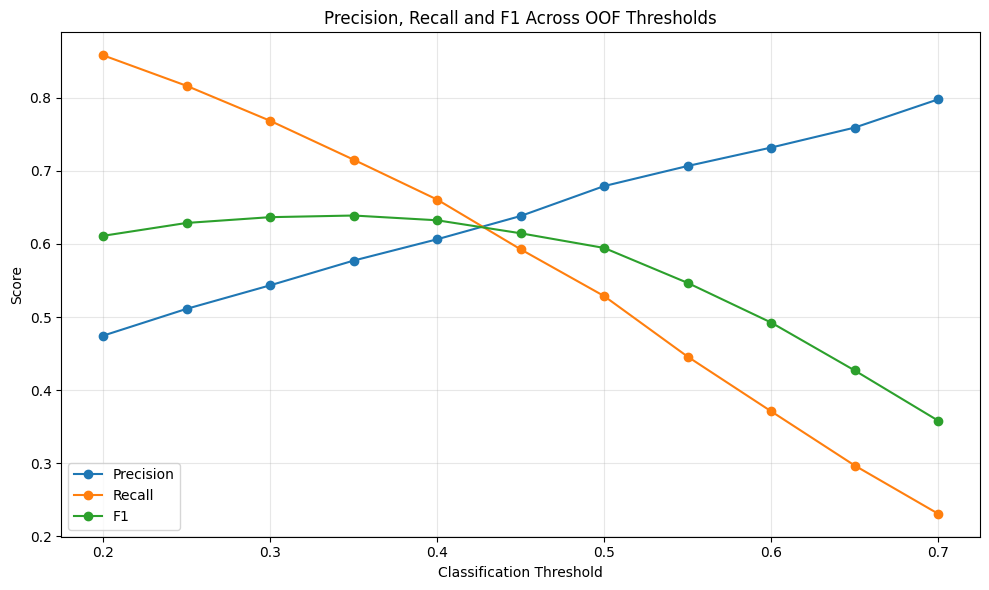

In [ ]:
# ============================================================
# STEP 7.9: PLOT THRESHOLD TRADE-OFF
# ============================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1"],
    marker="o",
    label="F1"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title(
    "Precision, Recall and F1 Across OOF Thresholds"
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# PHASE 8
# STEP 8.1: LOCK FINAL THRESHOLD
# ============================================================

final_threshold = 0.35

print("Final locked threshold:", final_threshold)

Final locked threshold: 0.35


In [ ]:
# ============================================================
# STEP 8.2: FIT FINAL MODEL ON ALL TRAINING DATA
# ============================================================

best_logistic_pipeline.fit(
    X_train_selected,
    y_train
)

print("Final tuned Logistic Regression fitted on all training data.")

Final tuned Logistic Regression fitted on all training data.


In [ ]:
# ============================================================
# STEP 8.3: GENERATE FINAL TEST PROBABILITIES
# ============================================================

test_probabilities = (
    best_logistic_pipeline
    .predict_proba(X_test_selected)[:, 1]
)

print("Test probabilities generated.")
print("Number of test probabilities:", len(test_probabilities))

Test probabilities generated.
Number of test probabilities: 1405


In [ ]:
# ============================================================
# STEP 8.4: APPLY LOCKED THRESHOLD
# ============================================================

test_predictions = (
    test_probabilities >= final_threshold
).astype(int)

print("Final test predictions created.")

Final test predictions created.


In [ ]:
# ============================================================
# STEP 8.5: FINAL TEST METRICS
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

test_accuracy = accuracy_score(
    y_test,
    test_predictions
)

test_precision = precision_score(
    y_test,
    test_predictions,
    zero_division=0
)

test_recall = recall_score(
    y_test,
    test_predictions
)

test_f1 = f1_score(
    y_test,
    test_predictions
)

test_roc_auc = roc_auc_score(
    y_test,
    test_probabilities
)

test_pr_auc = average_precision_score(
    y_test,
    test_probabilities
)

print("=" * 70)
print("FINAL UNTOUCHED TEST PERFORMANCE")
print("=" * 70)

print(f"Accuracy  : {test_accuracy:.4f}")
print(f"Precision : {test_precision:.4f}")
print(f"Recall    : {test_recall:.4f}")
print(f"F1 Score  : {test_f1:.4f}")
print(f"ROC-AUC   : {test_roc_auc:.4f}")
print(f"PR-AUC    : {test_pr_auc:.4f}")

FINAL UNTOUCHED TEST PERFORMANCE
Accuracy  : 0.7772
Precision : 0.5666
Recall    : 0.6747
F1 Score  : 0.6160
ROC-AUC   : 0.8414
PR-AUC    : 0.6532


In [ ]:
# ============================================================
# STEP 8.6: CONFUSION MATRIX
# ============================================================

from sklearn.metrics import confusion_matrix

tn, fp, fn, tp = confusion_matrix(
    y_test,
    test_predictions
).ravel()

print("=" * 60)
print("FINAL TEST CONFUSION MATRIX COUNTS")
print("=" * 60)

print("True Negatives  :", tn)
print("False Positives :", fp)
print("False Negatives :", fn)
print("True Positives  :", tp)

FINAL TEST CONFUSION MATRIX COUNTS
True Negatives  : 841
False Positives : 192
False Negatives : 121
True Positives  : 251


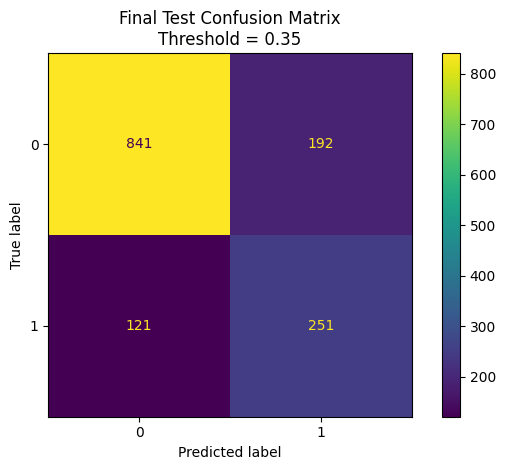

In [ ]:
# ============================================================
# STEP 8.7: CONFUSION MATRIX DISPLAY
# ============================================================

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions
)

plt.title(
    f"Final Test Confusion Matrix\nThreshold = {final_threshold}"
)

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# STEP 8.8: OOF VS FINAL TEST COMPARISON
# ============================================================

comparison_df = pd.DataFrame({

    "Metric": [
        "Precision",
        "Recall",
        "F1"
    ],

    "OOF_Training": [
        0.5772,
        0.7152,
        0.6388
    ],

    "Final_Test": [
        test_precision,
        test_recall,
        test_f1
    ]
})

comparison_df["Difference"] = (
    comparison_df["Final_Test"]
    -
    comparison_df["OOF_Training"]
)

print("=" * 70)
print("OOF VS FINAL TEST")
print("=" * 70)

print(
    comparison_df.round(4)
)

OOF VS FINAL TEST
      Metric  OOF_Training  Final_Test  Difference
0  Precision        0.5772      0.5666     -0.0106
1     Recall        0.7152      0.6747     -0.0405
2         F1        0.6388      0.6160     -0.0228


In [ ]:
# ============================================================
# STEP 8.9: DEFAULT 0.50 VS LOCKED 0.35
# FOR INTERPRETATION ONLY
# ============================================================

default_predictions = (
    test_probabilities >= 0.50
).astype(int)

threshold_comparison = pd.DataFrame({

    "Threshold": [
        0.35,
        0.50
    ],

    "Precision": [
        precision_score(
            y_test,
            test_predictions,
            zero_division=0
        ),
        precision_score(
            y_test,
            default_predictions,
            zero_division=0
        )
    ],

    "Recall": [
        recall_score(
            y_test,
            test_predictions
        ),
        recall_score(
            y_test,
            default_predictions
        )
    ],

    "F1": [
        f1_score(
            y_test,
            test_predictions
        ),
        f1_score(
            y_test,
            default_predictions
        )
    ]
})

print(
    threshold_comparison.round(4)
)

   Threshold  Precision  Recall      F1
0       0.35     0.5666  0.6747  0.6160
1       0.50     0.6655  0.5027  0.5727


In [ ]:
# ============================================================
# STEP 8.10: CLASSIFICATION REPORT
# ============================================================

from sklearn.metrics import classification_report

print("=" * 70)
print("FINAL CLASSIFICATION REPORT")
print("=" * 70)

print(
    classification_report(
        y_test,
        test_predictions,
        digits=4
    )
)

FINAL CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0     0.8742    0.8141    0.8431      1033
           1     0.5666    0.6747    0.6160       372

    accuracy                         0.7772      1405
   macro avg     0.7204    0.7444    0.7295      1405
weighted avg     0.7928    0.7772    0.7830      1405



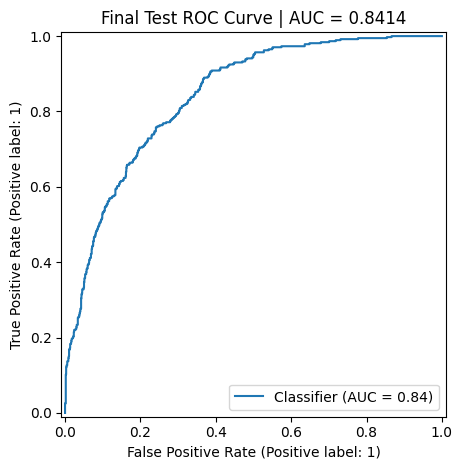

In [ ]:
# ============================================================
# STEP 8.11: ROC CURVE
# ============================================================

from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_predictions(
    y_test,
    test_probabilities
)

plt.title(
    f"Final Test ROC Curve | AUC = {test_roc_auc:.4f}"
)

plt.tight_layout()
plt.show()

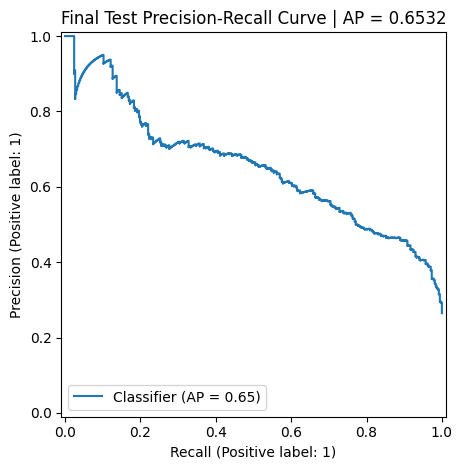

In [ ]:
# ============================================================
# STEP 8.12: PRECISION-RECALL CURVE
# ============================================================

from sklearn.metrics import PrecisionRecallDisplay

PrecisionRecallDisplay.from_predictions(
    y_test,
    test_probabilities
)

plt.title(
    f"Final Test Precision-Recall Curve | AP = {test_pr_auc:.4f}"
)

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# PHASE 9A
# STEP 9.1: EXTRACT FINAL LOGISTIC REGRESSION COEFFICIENTS
# ============================================================

import pandas as pd
import numpy as np

final_preprocessor = (
    best_logistic_pipeline
    .named_steps["preprocessor"]
)

final_logistic_model = (
    best_logistic_pipeline
    .named_steps["model"]
)

final_feature_names = (
    final_preprocessor
    .get_feature_names_out()
)

final_coefficients = (
    final_logistic_model.coef_[0]
)

coefficient_df = pd.DataFrame({
    "Feature": final_feature_names,
    "Coefficient": final_coefficients
})

coefficient_df["Abs_Coefficient"] = (
    coefficient_df["Coefficient"].abs()
)

coefficient_df = (
    coefficient_df
    .sort_values(
        "Abs_Coefficient",
        ascending=False
    )
    .reset_index(drop=True)
)

print("=" * 80)
print("LOGISTIC REGRESSION COEFFICIENTS")
print("=" * 80)

print(
    coefficient_df.head(20).round(4)
)

LOGISTIC REGRESSION COEFFICIENTS
                                      Feature  Coefficient  Abs_Coefficient
0            cat__InternetService_Fiber optic       2.3935           2.3935
1                      num__AvgChargePerMonth      -2.1527           2.1527
2                           num__ServiceCount       1.7091           1.7091
3                      cat__Contract_Two year      -1.5636           1.5636
4                                 num__tenure      -1.1972           1.1972
5                         num__MonthlyCharges      -1.1158           1.1158
6                     cat__OnlineSecurity_Yes      -0.8178           0.8178
7                        cat__TechSupport_Yes      -0.7398           0.7398
8                      cat__Contract_One year      -0.7077           0.7077
9                       cat__OnlineBackup_Yes      -0.6237           0.6237
10                          num__TotalCharges       0.6149           0.6149
11      cat__OnlineBackup_No internet service      -0.4

In [ ]:
# ============================================================
# STEP 9.2: CALCULATE ODDS RATIOS
# ============================================================

coefficient_df["Odds_Ratio"] = np.exp(
    coefficient_df["Coefficient"]
)

print(
    coefficient_df[
        [
            "Feature",
            "Coefficient",
            "Odds_Ratio"
        ]
    ]
    .head(20)
    .round(4)
)

                                      Feature  Coefficient  Odds_Ratio
0            cat__InternetService_Fiber optic       2.3935     10.9517
1                      num__AvgChargePerMonth      -2.1527      0.1162
2                           num__ServiceCount       1.7091      5.5240
3                      cat__Contract_Two year      -1.5636      0.2094
4                                 num__tenure      -1.1972      0.3020
5                         num__MonthlyCharges      -1.1158      0.3276
6                     cat__OnlineSecurity_Yes      -0.8178      0.4414
7                        cat__TechSupport_Yes      -0.7398      0.4772
8                      cat__Contract_One year      -0.7077      0.4928
9                       cat__OnlineBackup_Yes      -0.6237      0.5359
10                          num__TotalCharges       0.6149      1.8494
11      cat__OnlineBackup_No internet service      -0.4787      0.6196
12  cat__DeviceProtection_No internet service      -0.4787      0.6196
13    

In [ ]:
# ============================================================
# STEP 9.3: TOP POSITIVE AND NEGATIVE COEFFICIENTS
# ============================================================

top_positive = (
    coefficient_df[
        coefficient_df["Coefficient"] > 0
    ]
    .sort_values(
        "Coefficient",
        ascending=False
    )
    .head(10)
)

top_negative = (
    coefficient_df[
        coefficient_df["Coefficient"] < 0
    ]
    .sort_values(
        "Coefficient",
        ascending=True
    )
    .head(10)
)

print("=" * 70)
print("TOP FEATURES ASSOCIATED WITH HIGHER CHURN RISK")
print("=" * 70)

print(
    top_positive[
        ["Feature", "Coefficient", "Odds_Ratio"]
    ].round(4)
)

print("\n" + "=" * 70)
print("TOP FEATURES ASSOCIATED WITH LOWER CHURN RISK")
print("=" * 70)

print(
    top_negative[
        ["Feature", "Coefficient", "Odds_Ratio"]
    ].round(4)
)

TOP FEATURES ASSOCIATED WITH HIGHER CHURN RISK
                                Feature  Coefficient  Odds_Ratio
0      cat__InternetService_Fiber optic       2.3935     10.9517
2                     num__ServiceCount       1.7091      5.5240
10                    num__TotalCharges       0.6149      1.8494
17               cat__TenureGroup_Loyal       0.3654      1.4412
18            cat__PaperlessBilling_Yes       0.3436      1.4101
20  cat__PaymentMethod_Electronic check       0.2763      1.3182
22                   num__IsNewCustomer       0.1697      1.1849
23         cat__TenureGroup_Established       0.1470      1.1583
26                   num__SeniorCitizen       0.0978      1.1027
27                     cat__Partner_Yes       0.0323      1.0329

TOP FEATURES ASSOCIATED WITH LOWER CHURN RISK
                                      Feature  Coefficient  Odds_Ratio
1                      num__AvgChargePerMonth      -2.1527      0.1162
3                      cat__Contract_Two year    

In [ ]:
# ============================================================
# PHASE 9B
# STEP 9.4: TRANSFORM DATA USING FINAL FITTED PREPROCESSOR
# ============================================================

X_train_shap = (
    final_preprocessor
    .transform(X_train_selected)
)

X_test_shap = (
    final_preprocessor
    .transform(X_test_selected)
)

print(
    "SHAP train shape:",
    X_train_shap.shape
)

print(
    "SHAP test shape:",
    X_test_shap.shape
)

SHAP train shape: (5616, 29)
SHAP test shape: (1405, 29)


In [ ]:
import shap

In [ ]:
# ============================================================
# STEP 9.5: CREATE SHAP EXPLAINER
# ============================================================

explainer = shap.LinearExplainer(
    final_logistic_model,
    X_train_shap
)

shap_values = explainer(
    X_test_shap
)

print("SHAP values generated.")

SHAP values generated.


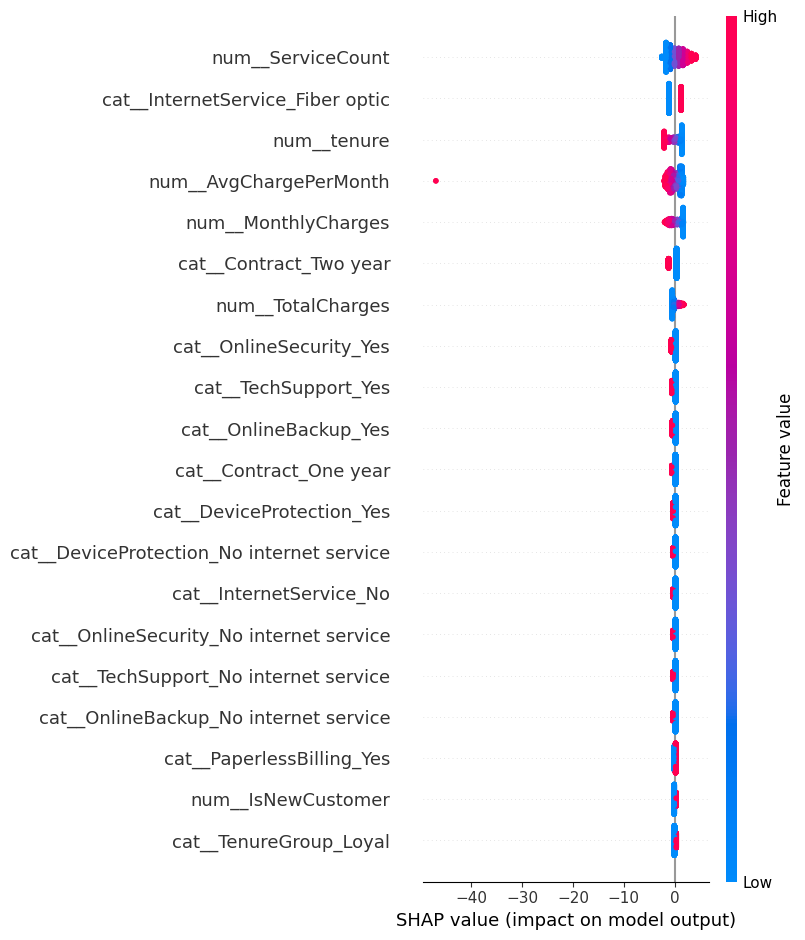

In [ ]:
# ============================================================
# STEP 9.6: GLOBAL SHAP FEATURE IMPORTANCE
# ============================================================

shap.summary_plot(
    shap_values.values,
    X_test_shap,
    feature_names=final_feature_names
)

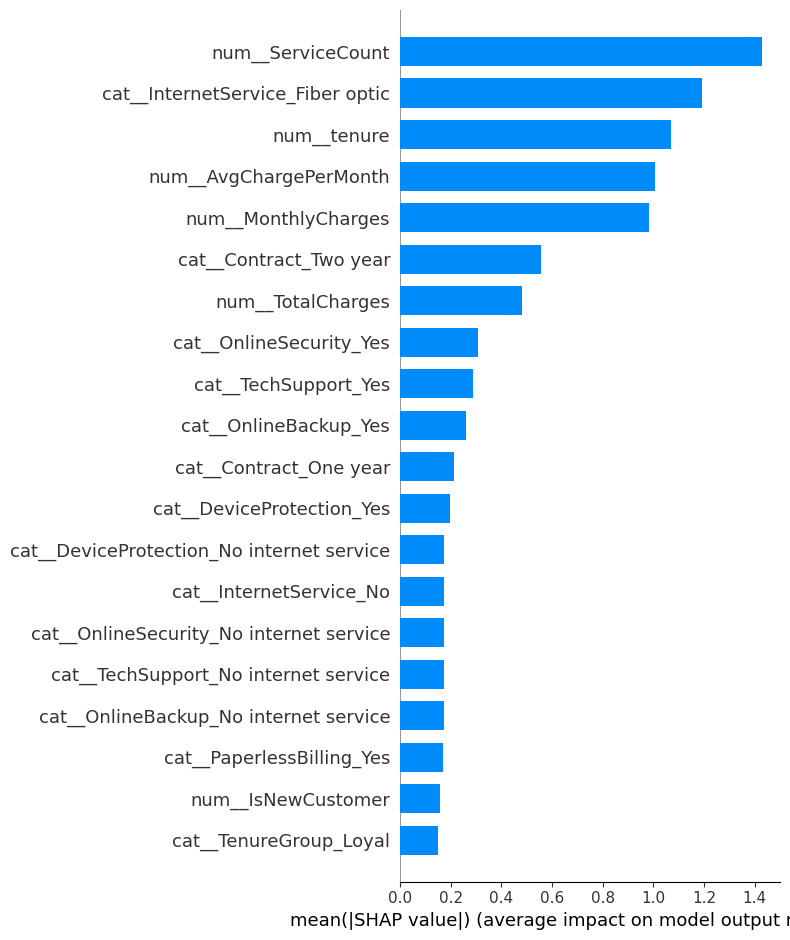

In [ ]:
shap.summary_plot(
    shap_values.values,
    X_test_shap,
    feature_names=final_feature_names,
    plot_type="bar"
)

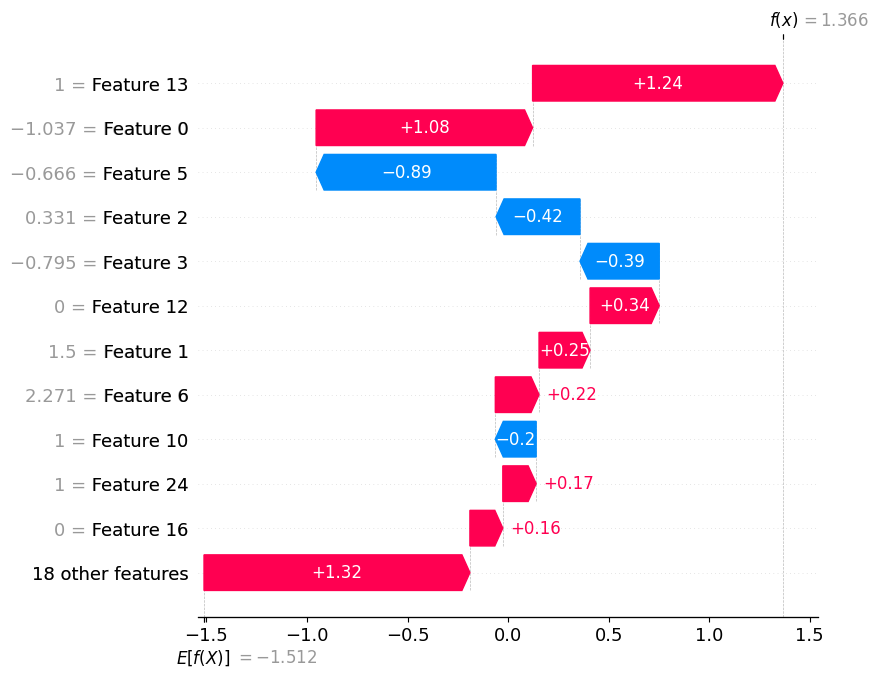

In [ ]:
customer_index = 0

shap.plots.waterfall(
    shap_values[customer_index],
    max_display=12
)

In [ ]:
# ============================================================
# STEP 9.7: CREATE CUSTOMER RISK TABLE
# ============================================================

risk_table = X_test_selected.copy()

risk_table["Actual_Churn"] = y_test.values

risk_table["Churn_Probability"] = (
    test_probabilities
)

risk_table["Predicted_Churn"] = (
    test_predictions
)

risk_table = risk_table.sort_values(
    "Churn_Probability",
    ascending=False
)

print(
    risk_table.head(20)
)

      tenure TenureGroup  IsNewCustomer        Contract  MonthlyCharges  \
2203       1         New              1  Month-to-month          100.80   
2739       1         New              1  Month-to-month           86.05   
6226       1         New              1  Month-to-month           93.30   
6353       2         New              1  Month-to-month           94.00   
3812       1         New              1  Month-to-month           74.20   
3741       2         New              1  Month-to-month           93.85   
982        1         New              1  Month-to-month           86.60   
5975       3         New              1  Month-to-month           94.60   
642        1         New              1  Month-to-month           89.55   
2031       1         New              1  Month-to-month           74.30   
1147       2         New              1  Month-to-month           95.15   
935        4         New              1  Month-to-month           83.25   
2459       1         New 

In [ ]:
import joblib

joblib.dump(
    best_logistic_pipeline,
    "churn_pipeline.pkl"
)
print("Model saved successfully.")

Model saved successfully.


In [ ]:
import sklearn
import joblib
import numpy
import pandas
import sys

print("Python:", sys.version)
print("scikit-learn:", sklearn.__version__)
print("joblib:", joblib.__version__)
print("numpy:", numpy.__version__)
print("pandas:", pandas.__version__)

Python: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
scikit-learn: 1.6.1
joblib: 1.6.0
numpy: 2.1.3
pandas: 2.2.3
